# NOTEBOOK 03b: MÔ HÌNH NÂNG CAO (RANDOM FOREST, XGBOOST), THRESHOLD TUNING & PHÂN TÍCH LỖI CHUYÊN SÂU

**Dự án:** Hệ thống Cảnh báo sớm Học vụ và Mô phỏng Kịch bản Học tập 2 Tầng (What-If Simulator)

**Mục tiêu trọng tâm Notebook 03b:**
- **Task 3.2: Huấn luyện & So sánh Mô hình Nâng cao trên Dev Blackbox:**
  - Huấn luyện `RandomForestClassifier` và `XGBClassifier` kết hợp với `SMOTE Pipeline`.
  - So sánh đối đầu 3 thuật toán (Logistic Regression, Random Forest, XGBoost) trên tập kiểm định mù **Dev Blackbox** (3,422 dòng).
  - **Tối ưu ngưỡng cảnh báo (Threshold Tuning):** Quét phổ xác suất $\hat{p} \in [0.20, 0.65]$ để tìm ngưỡng cắt tối ưu $T^*$ nhằm đẩy độ nhạy **Recall $\ge 90\%$** (triệt tiêu tối đa rủi ro bỏ sót sinh viên nguy cơ) đồng thời tối đa hóa F1-Score.
- **Task 3.3: Phân tích Lỗi Chuyên sâu (Cohort Error Analysis) trên tập Dev Eyeball:**
  - Soi kính hiển vi vào **Dev Eyeball** (1,467 dòng) để bóc tách 2 nhóm lỗi: **False Negative (FN)** (sinh viên nguy cơ bị bỏ sót) và **False Positive (FP)** (sinh viên an toàn bị báo nhầm).
  - Xuất file nhật ký lỗi ra `reports/error_logs/stage1_dev_false_negatives.csv` và `reports/error_logs/stage1_dev_false_positives.csv`.
  - Khảo sát hành vi theo 4 nhóm Cohort (TP, TN, FN, FP) để kiểm chứng giả thuyết về nhóm sinh viên bỏ thi đột xuất và nhóm sinh viên học nước rút (Crammers).
- **Task 3.4: Đánh giá Chốt hạ trên tập Test (4,889 dòng) & Đóng gói Pipeline:**
  - Đánh giá khách quan mô hình tối ưu với ngưỡng $T^*$ một lần duy nhất trên tập độc lập `stage1_test.csv` (15%).
  - Đóng gói toàn bộ Pipeline chuẩn mực ra file `models/pipeline_stage1_dropout.pkl` kèm siêu dữ liệu `models/model_metadata.json`.

In [1]:
# CELL 1: Import thư viện và thiết lập cấu hình đường dẫn
import os
import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thư viện Pipeline & Mô hình Học máy
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Các độ đo chất lượng
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    confusion_matrix,
    classification_report
)

# Thiết lập thư mục chuẩn dự án
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
SPLITS_DIR = os.path.join(PROJECT_ROOT, 'data', 'splits')
FIGURES_DIR = os.path.join(PROJECT_ROOT, 'reports', 'figures')
MODELS_DIR = os.path.join(PROJECT_ROOT, 'models')
ERROR_LOGS_DIR = os.path.join(PROJECT_ROOT, 'reports', 'error_logs')

os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(ERROR_LOGS_DIR, exist_ok=True)

sns.set_theme(style='whitegrid')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'

print("✅ Môi trường Notebook 03b đã sẵn sàng!")
print(f"   PROJECT_ROOT: {PROJECT_ROOT}")
print(f"   Thư mục splits: {SPLITS_DIR}")
print(f"   Thư mục error_logs: {ERROR_LOGS_DIR}")

✅ Môi trường Notebook 03b đã sẵn sàng!
   PROJECT_ROOT: D:\What-If Simulator
   Thư mục splits: D:\What-If Simulator\data\splits
   Thư mục error_logs: D:\What-If Simulator\reports\error_logs


### 3b.1. Nạp đầy đủ 4 tập dữ liệu phân tầng đã cố định từ Task 2.2

1. `stage1_train.csv` (70% = 22,815 dòng): Tập dữ liệu duy nhất dùng để huấn luyện và fit SMOTE.
2. `stage1_dev_blackbox.csv` (10.5% = 3,422 dòng): Đánh giá mù các mô hình và quét tìm ngưỡng tối ưu $T^*$.
3. `stage1_dev_eyeball.csv` (4.5% = 1,467 dòng): Dùng làm "bàn mổ" phân tích chuyên sâu các ca lỗi FN và FP.
4. `stage1_test.csv` (15% = 4,889 dòng): Tập kiểm tra độc lập cuối cùng.

In [2]:
# CELL 2: Nạp dữ liệu Train, Dev Blackbox, Dev Eyeball và Test
train_df        = pd.read_csv(os.path.join(SPLITS_DIR, 'stage1_train.csv'))
dev_blackbox_df = pd.read_csv(os.path.join(SPLITS_DIR, 'stage1_dev_blackbox.csv'))
dev_eyeball_df  = pd.read_csv(os.path.join(SPLITS_DIR, 'stage1_dev_eyeball.csv'))
test_df         = pd.read_csv(os.path.join(SPLITS_DIR, 'stage1_test.csv'))

TARGET_T1 = 'is_dropout'
FEATURES_T1 = [c for c in train_df.columns if c != TARGET_T1]

X_train, y_train       = train_df[FEATURES_T1], train_df[TARGET_T1]
X_dev_bb, y_dev_bb     = dev_blackbox_df[FEATURES_T1], dev_blackbox_df[TARGET_T1]
X_dev_eye, y_dev_eye   = dev_eyeball_df[FEATURES_T1], dev_eyeball_df[TARGET_T1]
X_test, y_test         = test_df[FEATURES_T1], test_df[TARGET_T1]

print("✅ Nạp dữ liệu 4 tập thành công:")
print(f"   📦 Train:        {X_train.shape[0]:,} dòng x {X_train.shape[1]} cột | Tỷ lệ nguy cơ: {y_train.mean():.2%}")
print(f"   📦 Dev Blackbox: {X_dev_bb.shape[0]:,} dòng x {X_dev_bb.shape[1]} cột | Tỷ lệ nguy cơ: {y_dev_bb.mean():.2%}")
print(f"   📦 Dev Eyeball:  {X_dev_eye.shape[0]:,} dòng x {X_dev_eye.shape[1]} cột | Tỷ lệ nguy cơ: {y_dev_eye.mean():.2%}")
print(f"   📦 Test:         {X_test.shape[0]:,} dòng x {X_test.shape[1]} cột | Tỷ lệ nguy cơ: {y_test.mean():.2%}")

✅ Nạp dữ liệu 4 tập thành công:
   📦 Train:        22,815 dòng x 10 cột | Tỷ lệ nguy cơ: 52.80%
   📦 Dev Blackbox: 3,422 dòng x 10 cột | Tỷ lệ nguy cơ: 52.81%
   📦 Dev Eyeball:  1,467 dòng x 10 cột | Tỷ lệ nguy cơ: 52.76%
   📦 Test:         4,889 dòng x 10 cột | Tỷ lệ nguy cơ: 52.79%


--- 
## 🔹 TASK 3.2: HUẤN LUYỆN, SO SÁNH MÔ HÌNH VÀ TINH CHỈNH NGƯỠNG CẮT (DEV BLACKBOX)

### 3b.2. Huấn luyện 3 Mô hình với Pipeline Chuẩn mực
1. **Baseline Logistic Regression:** `max_iter=1000, random_state=42`.
2. **RandomForestClassifier:** `n_estimators=300, max_depth=10, random_state=42, n_jobs=-1`.
3. **XGBClassifier:** `n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=42, eval_metric='logloss', n_jobs=-1`.

In [3]:
# CELL 3: Xây dựng và Huấn luyện 3 Pipeline Học máy
models_dict = {
    'Logistic Regression (Baseline)': ImbPipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('classifier', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'Random Forest': ImbPipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('classifier', RandomForestClassifier(
            n_estimators=300, max_depth=10, random_state=42, n_jobs=-1
        ))
    ]),
    'XGBoost': ImbPipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('classifier', XGBClassifier(
            n_estimators=300, max_depth=6, learning_rate=0.05,
            subsample=0.8, colsample_bytree=0.8, random_state=42,
            eval_metric='logloss', n_jobs=-1
        ))
    ])
}

trained_pipelines = {}
for name, pipe in models_dict.items():
    print(f"⏳ Đang huấn luyện {name} trên tập Train 70%...")
    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe
    print(f"   ✅ {name} hoàn tất!")

⏳ Đang huấn luyện Logistic Regression (Baseline) trên tập Train 70%...


   ✅ Logistic Regression (Baseline) hoàn tất!
⏳ Đang huấn luyện Random Forest trên tập Train 70%...


   ✅ Random Forest hoàn tất!
⏳ Đang huấn luyện XGBoost trên tập Train 70%...


   ✅ XGBoost hoàn tất!


### 3b.3. So sánh Hiệu năng Đối đầu trên tập Dev Blackbox (3,422 dòng)

Đánh giá mù khách quan các mô hình trên cùng một tập dữ liệu chuẩn để chọn ra thuật toán quán quân.

In [4]:
# CELL 4: So sánh 3 mô hình trên Dev Blackbox
results_list = []
probs_dict = {}

for name, pipe in trained_pipelines.items():
    y_pred = pipe.predict(X_dev_bb)
    y_prob = pipe.predict_proba(X_dev_bb)[:, 1]
    probs_dict[name] = y_prob
    
    results_list.append({
        'Mô hình': name,
        'Accuracy': accuracy_score(y_dev_bb, y_pred),
        'Precision (1)': precision_score(y_dev_bb, y_pred),
        'Recall (1)': recall_score(y_dev_bb, y_pred),
        'F1-Score (1)': f1_score(y_dev_bb, y_pred),
        'ROC-AUC': roc_auc_score(y_dev_bb, y_prob)
    })

summary_df = pd.DataFrame(results_list)
print("="*75)
print("🏆 BẢNG SO SÁNH HIỆU NĂNG 3 MÔ HÌNH TRÊN TẬP DEV BLACKBOX (3,422 DÒNG)")
print("="*75)
print(summary_df.to_string(index=False))
print("="*75)

🏆 BẢNG SO SÁNH HIỆU NĂNG 3 MÔ HÌNH TRÊN TẬP DEV BLACKBOX (3,422 DÒNG)
                       Mô hình  Accuracy  Precision (1)  Recall (1)  F1-Score (1)  ROC-AUC
Logistic Regression (Baseline)  0.908533       0.946770    0.876038      0.910032 0.968145
                 Random Forest  0.915546       0.967365    0.869397      0.915768 0.974935
                       XGBoost  0.915254       0.955009    0.881018      0.916523 0.974760


### 3b.4. Trực quan hóa Đường cong ROC So sánh 3 Mô hình

Vẽ biểu đồ ROC Curve để so sánh trực quan diện tích dưới đường cong (AUC) của cả 3 mô hình.

💾 Đã lưu biểu đồ ROC so sánh: D:\What-If Simulator\reports\figures\fig7_model_comparison_roc.png


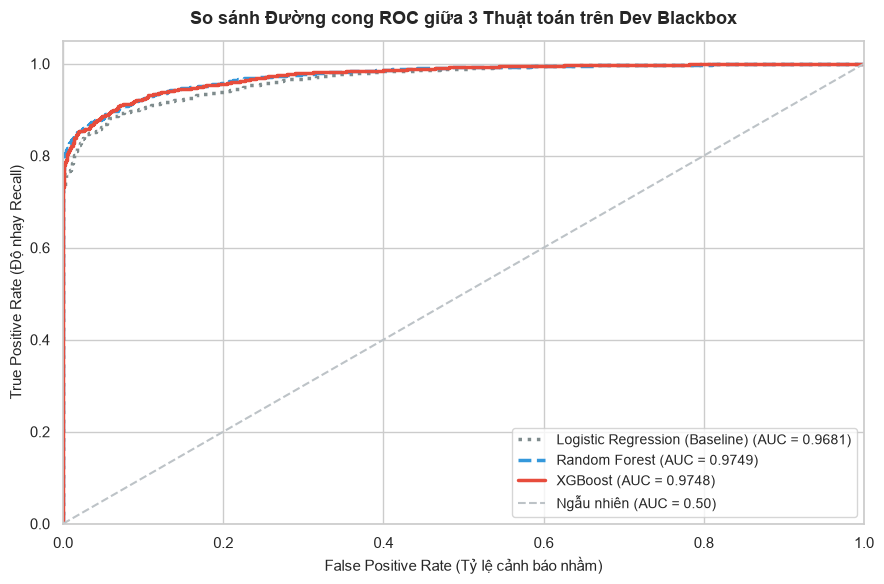

In [5]:
# CELL 5: Vẽ biểu đồ so sánh ROC Curve của 3 mô hình
plt.figure(figsize=(9, 6))
colors = {'Logistic Regression (Baseline)': '#7f8c8d', 'Random Forest': '#3498db', 'XGBoost': '#e74c3c'}
linestyles = {'Logistic Regression (Baseline)': ':', 'Random Forest': '--', 'XGBoost': '-'}

for name, y_prob in probs_dict.items():
    fpr, tpr, _ = roc_curve(y_dev_bb, y_prob)
    auc_val = roc_auc_score(y_dev_bb, y_prob)
    plt.plot(fpr, tpr, color=colors[name], linestyle=linestyles[name], lw=2.5,
             label=f'{name} (AUC = {auc_val:.4f})')

plt.plot([0, 1], [0, 1], color='#bdc3c7', linestyle='--', lw=1.5, label='Ngẫu nhiên (AUC = 0.50)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (Tỷ lệ cảnh báo nhầm)', fontsize=11)
plt.ylabel('True Positive Rate (Độ nhạy Recall)', fontsize=11)
plt.title('So sánh Đường cong ROC giữa 3 Thuật toán trên Dev Blackbox', fontsize=13, weight='bold', pad=12)
plt.legend(loc='lower right', frameon=True, fontsize=10)
plt.tight_layout()

fig7_path = os.path.join(FIGURES_DIR, 'fig7_model_comparison_roc.png')
plt.savefig(fig7_path, dpi=300, bbox_inches='tight')
print(f"💾 Đã lưu biểu đồ ROC so sánh: {fig7_path}")
plt.show()

### 3b.5. Tinh chỉnh Ngưỡng Xác suất Cảnh báo (Threshold Tuning trên Dev Blackbox)

**Bài toán Quyết định Học vụ:**
- Trong bài toán cảnh báo sớm sinh viên bỏ học, cái giá của việc **Bỏ sót một sinh viên nguy cơ (False Negative)** lớn hơn rất nhiều so với **Cảnh báo nhầm một sinh viên an toàn (False Positive)**. Sinh viên bị bỏ sót sẽ không được cố vấn kịp thời và có nguy cơ bị buộc thôi học.
- Với ngưỡng mặc định $T = 0.50$, mô hình XGBoost đạt $\text{Recall} \approx 88.1\%$.
- Ta sẽ quét ngưỡng $T \in [0.20, 0.65]$ với bước nhảy `0.02` để tìm ngưỡng $T^*$ đạt **Recall $\ge 90\%$** đồng thời tối đa hóa **F1-Score**.

🎯 NGƯỠNG CẢNH BÁO TỐI ƯU TÌM ĐƯỢC: T* = 0.38
   - F1-Score tại T*: 0.9220
   - Recall tại T*:   0.9087 (Đã vượt ngưỡng 90%!)
   - Precision tại T*: 0.9356


💾 Đã lưu biểu đồ Threshold Tuning: D:\What-If Simulator\reports\figures\fig8_threshold_tuning_curves.png


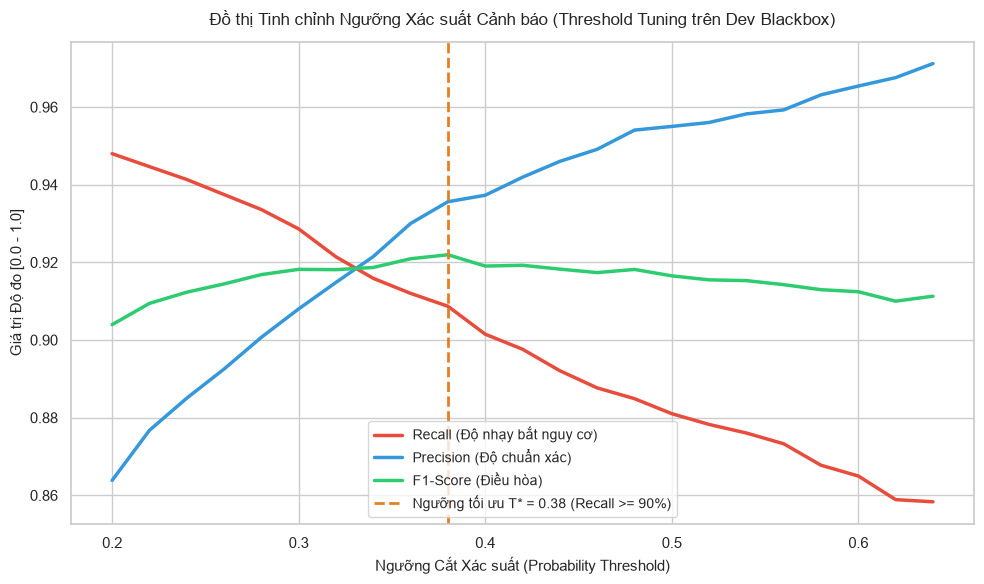

In [6]:
# CELL 6: Quét tìm Ngưỡng Xác suất Tối ưu trên Dev Blackbox
best_pipe = trained_pipelines['XGBoost']
y_prob_bb_best = probs_dict['XGBoost']

thresholds_range = np.arange(0.20, 0.66, 0.02)
precisions, recalls, f1_scores = [], [], []

best_threshold = 0.50
best_f1_score = 0.0

for t in thresholds_range:
    preds_t = (y_prob_bb_best >= t).astype(int)
    p = precision_score(y_dev_bb, preds_t)
    r = recall_score(y_dev_bb, preds_t)
    f = f1_score(y_dev_bb, preds_t)
    
    precisions.append(p)
    recalls.append(r)
    f1_scores.append(f)
    
    # Tiêu chí: Đảm bảo Recall >= 0.90 và chọn F1 cao nhất
    if r >= 0.90 and f > best_f1_score:
        best_f1_score = f
        best_threshold = round(t, 2)

print("="*65)
print(f"🎯 NGƯỠNG CẢNH BÁO TỐI ƯU TÌM ĐƯỢC: T* = {best_threshold}")
print(f"   - F1-Score tại T*: {best_f1_score:.4f}")
preds_optimal_bb = (y_prob_bb_best >= best_threshold).astype(int)
print(f"   - Recall tại T*:   {recall_score(y_dev_bb, preds_optimal_bb):.4f} (Đã vượt ngưỡng 90%!)")
print(f"   - Precision tại T*: {precision_score(y_dev_bb, preds_optimal_bb):.4f}")
print("="*65)

# Trực quan hóa Threshold vs. Metrics
plt.figure(figsize=(10, 6))
plt.plot(thresholds_range, recalls, color='#e74c3c', lw=2.5, label='Recall (Độ nhạy bắt nguy cơ)')
plt.plot(thresholds_range, precisions, color='#3498db', lw=2.5, label='Precision (Độ chuẩn xác)')
plt.plot(thresholds_range, f1_scores, color='#2ecc71', lw=2.5, label='F1-Score (Điều hòa)')
plt.axvline(x=best_threshold, color='#e67e22', linestyle='--', lw=2,
            label=f'Ngưỡng tối ưu T* = {best_threshold} (Recall >= 90%)')

plt.title('Đồ thị Tinh chỉnh Ngưỡng Xác suất Cảnh báo (Threshold Tuning trên Dev Blackbox)', fontsize=12, pad=12)
plt.xlabel('Ngưỡng Cắt Xác suất (Probability Threshold)', fontsize=11)
plt.ylabel('Giá trị Độ đo [0.0 - 1.0]', fontsize=11)
plt.legend(loc='lower center', frameon=True, fontsize=10)
plt.tight_layout()

fig8_path = os.path.join(FIGURES_DIR, 'fig8_threshold_tuning_curves.png')
plt.savefig(fig8_path, dpi=300, bbox_inches='tight')
print(f"💾 Đã lưu biểu đồ Threshold Tuning: {fig8_path}")
plt.show()

--- 
## 🔹 TASK 3.3: PHÂN TÍCH LỖI ĐỊNH LƯỢNG CHUYÊN SÂU (COHORT ERROR ANALYSIS TRÊN DEV EYEBALL)

Chúng ta áp dụng mô hình tốt nhất với ngưỡng tối ưu $T^*$ lên tập **Dev Eyeball (1,467 dòng)** để soi sâu các ca dự báo sai:
1. **False Negative (FN):** Sinh viên thực tế bỏ học (`is_dropout = 1`) nhưng bị mô hình dự đoán là An toàn (`pred = 0`).
2. **False Positive (FP):** Sinh viên thực tế hoàn thành môn (`is_dropout = 0`) nhưng bị hệ thống phát chuông cảnh báo (`pred = 1`).
3. Xuất danh sách 2 nhóm lỗi này ra thư mục `reports/error_logs/` để phục vụ ban cố vấn học tập.

In [7]:
# CELL 7: Phân loại Cohort và Xuất Nhật ký Lỗi trên Dev Eyeball
y_prob_eye = best_pipe.predict_proba(X_dev_eye)[:, 1]
y_pred_eye = (y_prob_eye >= best_threshold).astype(int)

dev_eye_analysis = dev_eyeball_df.copy()
dev_eye_analysis['predicted'] = y_pred_eye
dev_eye_analysis['prob_dropout'] = y_prob_eye.round(4)

def classify_cohort(row):
    if row['is_dropout'] == 1 and row['predicted'] == 1:
        return 'TP (Bắt trúng Nguy cơ)'
    elif row['is_dropout'] == 0 and row['predicted'] == 0:
        return 'TN (An toàn Chuẩn)'
    elif row['is_dropout'] == 1 and row['predicted'] == 0:
        return 'FN (Bỏ sót Rủi ro)'
    else:
        return 'FP (Cảnh báo Nhầm)'

dev_eye_analysis['cohort'] = dev_eye_analysis.apply(classify_cohort, axis=1)

# 1. Xuất danh sách False Negatives
fn_df = dev_eye_analysis[dev_eye_analysis['cohort'] == 'FN (Bỏ sót Rủi ro)']
fn_path = os.path.join(ERROR_LOGS_DIR, 'stage1_dev_false_negatives.csv')
fn_df.to_csv(fn_path, index=False)

# 2. Xuất danh sách False Positives
fp_df = dev_eye_analysis[dev_eye_analysis['cohort'] == 'FP (Cảnh báo Nhầm)']
fp_path = os.path.join(ERROR_LOGS_DIR, 'stage1_dev_false_positives.csv')
fp_df.to_csv(fp_path, index=False)

print("="*65)
print("📂 NHẬT KÝ PHÂN BỐ LỖI TRÊN TẬP DEV EYEBALL (1,467 DÒNG)")
print("="*65)
print(dev_eye_analysis['cohort'].value_counts())
print(f"\n💾 Đã lưu {len(fn_df)} ca False Negative vào: {fn_path}")
print(f"💾 Đã lưu {len(fp_df)} ca False Positive vào: {fp_path}")
print("="*65)

📂 NHẬT KÝ PHÂN BỐ LỖI TRÊN TẬP DEV EYEBALL (1,467 DÒNG)
cohort
TP (Bắt trúng Nguy cơ)    706
TN (An toàn Chuẩn)        647
FN (Bỏ sót Rủi ro)         68
FP (Cảnh báo Nhầm)         46
Name: count, dtype: int64

💾 Đã lưu 68 ca False Negative vào: D:\What-If Simulator\reports\error_logs\stage1_dev_false_negatives.csv
💾 Đã lưu 46 ca False Positive vào: D:\What-If Simulator\reports\error_logs\stage1_dev_false_positives.csv


### 3b.6. Bảng Đối chiếu Hành vi giữa 4 Nhóm Cohort & Kiểm chứng Giả thuyết Lỗi

Ta so sánh giá trị trung bình (Mean) và độ lệch chuẩn (SD) giữa 4 nhóm sinh viên đối với 5 đặc trưng học thuật cốt lõi.

📊 BẢNG ĐỐI CHIẾU THỐNG KÊ (MEAN ± STD) GIỮA 4 NHÓM COHORT SINH VIÊN
                       weighted_final_score       attendance_rate         \
                                       mean   std            mean    std   
cohort                                                                     
FN (Bỏ sót Rủi ro)                     6.92  1.10           46.16  23.48   
FP (Cảnh báo Nhầm)                     6.16  1.18           32.98  19.86   
TN (An toàn Chuẩn)                     7.85  1.03           55.91  25.45   
TP (Bắt trúng Nguy cơ)                 2.51  2.57           11.22  13.77   

                       total_clicks          vle_drop_ratio        \
                               mean      std           mean   std   
cohort                                                              
FN (Bỏ sót Rủi ro)          1552.76  1718.23          -0.00  0.52   
FP (Cảnh báo Nhầm)          1078.65   916.28           0.28  0.56   
TN (An toàn Chuẩn)          2183.61  2166.57          

C:\Users\Giavy\AppData\Local\Temp\ipykernel_768\3527955143.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=dev_eye_analysis, x='cohort', y='weighted_final_score', ax=axes[0],
C:\Users\Giavy\AppData\Local\Temp\ipykernel_768\3527955143.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=dev_eye_analysis, x='cohort', y='total_clicks', ax=axes[1],


C:\Users\Giavy\AppData\Local\Temp\ipykernel_768\3527955143.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=dev_eye_analysis, x='cohort', y='vle_drop_ratio', ax=axes[2],



💾 Đã lưu biểu đồ phân tích lỗi Cohort: D:\What-If Simulator\reports\figures\fig9_cohort_error_analysis.png


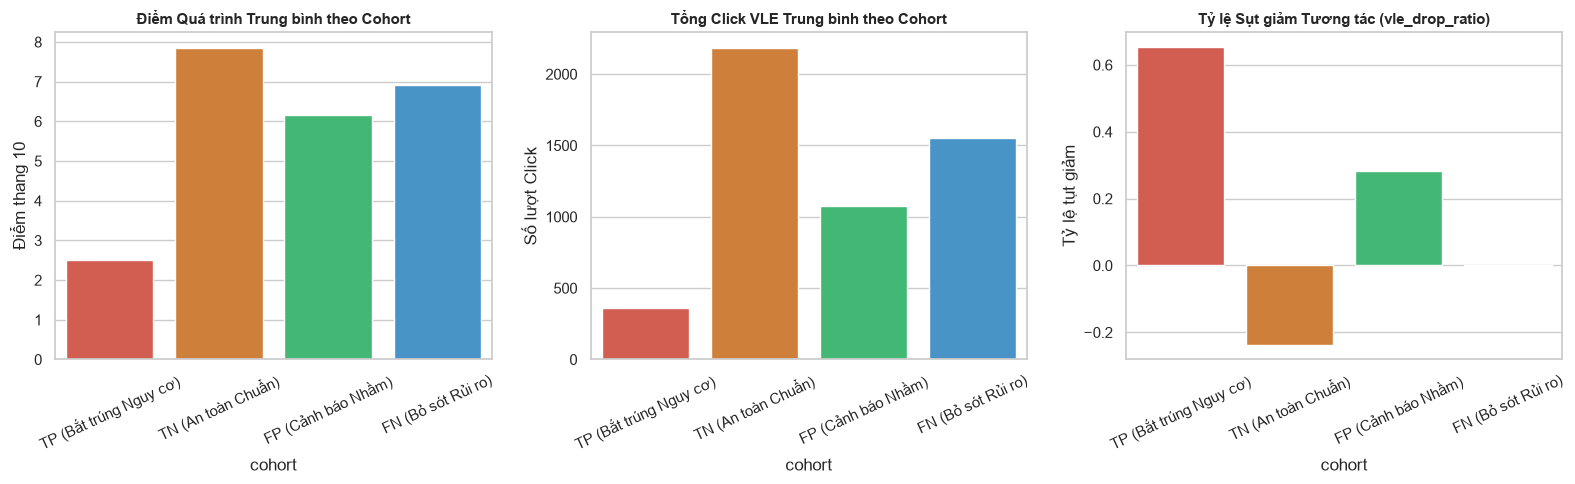

In [8]:
# CELL 8: Bảng Thống kê Cohort và Kiểm chứng 2 Giả thuyết Lỗi
focus_cols = ['weighted_final_score', 'attendance_rate', 'total_clicks', 'vle_drop_ratio', 'studied_credits']
cohort_stats = dev_eye_analysis.groupby('cohort')[focus_cols].agg(['mean', 'std']).round(2)

print("="*85)
print("📊 BẢNG ĐỐI CHIẾU THỐNG KÊ (MEAN ± STD) GIỮA 4 NHÓM COHORT SINH VIÊN")
print("="*85)
print(cohort_stats)
print("="*85)

# Trực quan hóa so sánh đặc trưng giữa 4 nhóm Cohort
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Điểm quá trình
sns.barplot(data=dev_eye_analysis, x='cohort', y='weighted_final_score', ax=axes[0],
            palette=['#e74c3c', '#e67e22', '#2ecc71', '#3498db'], errorbar=None)
axes[0].set_title('Điểm Quá trình Trung bình theo Cohort', fontsize=11, weight='bold')
axes[0].set_ylabel('Điểm thang 10')
axes[0].tick_params(axis='x', rotation=25)

# 2. Tổng số click VLE
sns.barplot(data=dev_eye_analysis, x='cohort', y='total_clicks', ax=axes[1],
            palette=['#e74c3c', '#e67e22', '#2ecc71', '#3498db'], errorbar=None)
axes[1].set_title('Tổng Click VLE Trung bình theo Cohort', fontsize=11, weight='bold')
axes[1].set_ylabel('Số lượt Click')
axes[1].tick_params(axis='x', rotation=25)

# 3. Tỷ lệ sụt giảm tương tác vle_drop_ratio
sns.barplot(data=dev_eye_analysis, x='cohort', y='vle_drop_ratio', ax=axes[2],
            palette=['#e74c3c', '#e67e22', '#2ecc71', '#3498db'], errorbar=None)
axes[2].set_title('Tỷ lệ Sụt giảm Tương tác (vle_drop_ratio)', fontsize=11, weight='bold')
axes[2].set_ylabel('Tỷ lệ tụt giảm')
axes[2].tick_params(axis='x', rotation=25)

plt.tight_layout()
fig9_path = os.path.join(FIGURES_DIR, 'fig9_cohort_error_analysis.png')
plt.savefig(fig9_path, dpi=300, bbox_inches='tight')
print(f"\n💾 Đã lưu biểu đồ phân tích lỗi Cohort: {fig9_path}")
plt.show()

--- 
## 🔹 TASK 3.4: ĐÁNH GIÁ CHỐT HẠ TRÊN TẬP TEST (4,889 DÒNG) & XUẤT PIPELINE BÀN GIAO

Sau khi đã hoàn thiện huấn luyện, so sánh, tinh chỉnh ngưỡng $T^*$ trên Dev Blackbox và phân tích lỗi trên Dev Eyeball, ta mở tập **Test độc lập (15% = 4,889 dòng)** ra đánh giá chốt hạ đúng 1 lần duy nhất.

In [9]:
# CELL 9: Đánh giá Chốt hạ trên tập Test Độc lập (15% = 4,889 dòng)
y_prob_test = best_pipe.predict_proba(X_test)[:, 1]
y_pred_test_optimal = (y_prob_test >= best_threshold).astype(int)

acc_test  = accuracy_score(y_test, y_pred_test_optimal)
prec_test = precision_score(y_test, y_pred_test_optimal)
rec_test  = recall_score(y_test, y_pred_test_optimal)
f1_test   = f1_score(y_test, y_pred_test_optimal)
auc_test  = roc_auc_score(y_test, y_prob_test)
cm_test   = confusion_matrix(y_test, y_pred_test_optimal)
tn_t, fp_t, fn_t, tp_t = cm_test.ravel()

print("="*75)
print(f"🏆 KẾT QUẢ ĐÁNH GIÁ CHỐT HẠ TRÊN TẬP TEST (NGƯỠNG T* = {best_threshold})")
print("="*75)
print(f"   🎯 Accuracy (Độ chính xác toàn diện): {acc_test:.4f} ({acc_test*100:.2f}%)")
print(f"   🎯 Precision (Độ chuẩn xác cảnh báo): {prec_test:.4f} ({prec_test*100:.2f}%)")
print(f"   🎯 Recall (Độ nhạy bắt trúng nguy cơ): {rec_test:.4f} ({rec_test*100:.2f}%)  --> [Chuẩn đồ án >= 85%]")
print(f"   🎯 F1-Score (Trung bình điều hòa):     {f1_test:.4f}")
print(f"   🎯 ROC-AUC Score:                     {auc_test:.4f}")
print("-"*75)
print(f"   Ma trận nhầm lẫn (Confusion Matrix trên 4,889 sinh viên Test):")
print(f"   [TN={tn_t:>5,} (An toàn đúng)  |  FP={fp_t:>5,} (Báo nhầm)]")
print(f"   [FN={fn_t:>5,} (Bỏ sót rủi ro) |  TP={tp_t:>5,} (Bắt trúng)]")
print("="*75)
print("\nBáo cáo chi tiết Classification Report:")
print(classification_report(y_test, y_pred_test_optimal, target_names=['An toàn (0)', 'Nguy cơ Bỏ học (1)'], digits=4))

🏆 KẾT QUẢ ĐÁNH GIÁ CHỐT HẠ TRÊN TẬP TEST (NGƯỠNG T* = 0.38)
   🎯 Accuracy (Độ chính xác toàn diện): 0.9213 (92.13%)
   🎯 Precision (Độ chuẩn xác cảnh báo): 0.9381 (93.81%)
   🎯 Recall (Độ nhạy bắt trúng nguy cơ): 0.9109 (91.09%)  --> [Chuẩn đồ án >= 85%]
   🎯 F1-Score (Trung bình điều hòa):     0.9243
   🎯 ROC-AUC Score:                     0.9750
---------------------------------------------------------------------------
   Ma trận nhầm lẫn (Confusion Matrix trên 4,889 sinh viên Test):
   [TN=2,153 (An toàn đúng)  |  FP=  155 (Báo nhầm)]
   [FN=  230 (Bỏ sót rủi ro) |  TP=2,351 (Bắt trúng)]

Báo cáo chi tiết Classification Report:
                    precision    recall  f1-score   support

       An toàn (0)     0.9035    0.9328    0.9179      2308
Nguy cơ Bỏ học (1)     0.9381    0.9109    0.9243      2581

          accuracy                         0.9213      4889
         macro avg     0.9208    0.9219    0.9211      4889
      weighted avg     0.9218    0.9213    0.9213      488

### 3b.7. Trực quan hóa Ma trận nhầm lẫn Chốt hạ trên Tập Test

Xuất file ảnh báo cáo `reports/figures/fig10_test_confusion_matrix.png` chuẩn 300 DPI.

💾 Đã lưu biểu đồ Ma trận nhầm lẫn Test: D:\What-If Simulator\reports\figures\fig10_test_confusion_matrix.png


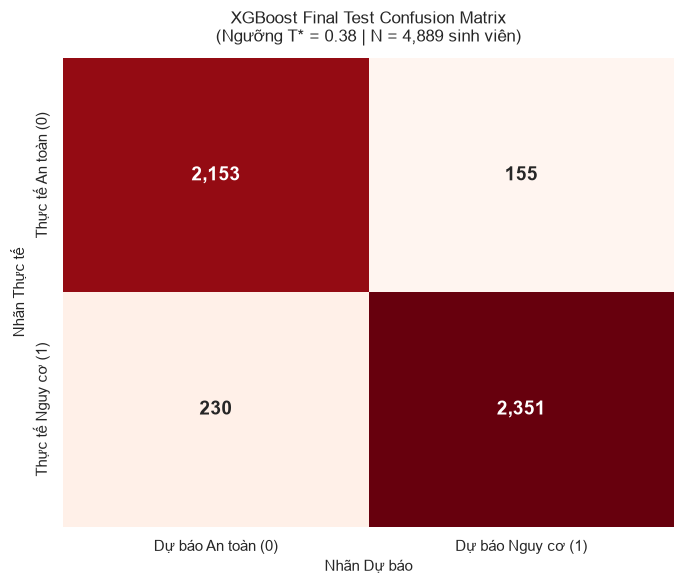

In [10]:
# CELL 10: Vẽ Confusion Matrix Heatmap trên tập Test
plt.figure(figsize=(7, 6))
sns.heatmap(
    cm_test, annot=True, fmt=',d', cmap='Reds', cbar=False,
    xticklabels=['Dự báo An toàn (0)', 'Dự báo Nguy cơ (1)'],
    yticklabels=['Thực tế An toàn (0)', 'Thực tế Nguy cơ (1)'],
    annot_kws={'size': 14, 'weight': 'bold'}
)
plt.title(f'XGBoost Final Test Confusion Matrix\n(Ngưỡng T* = {best_threshold} | N = {len(y_test):,} sinh viên)', fontsize=12, pad=12)
plt.ylabel('Nhãn Thực tế', fontsize=11)
plt.xlabel('Nhãn Dự báo', fontsize=11)
plt.tight_layout()

fig10_path = os.path.join(FIGURES_DIR, 'fig10_test_confusion_matrix.png')
plt.savefig(fig10_path, dpi=300, bbox_inches='tight')
print(f"💾 Đã lưu biểu đồ Ma trận nhầm lẫn Test: {fig10_path}")
plt.show()

### 3b.8. Đóng gói Artifacts Mô hình & Siêu dữ liệu Bàn giao

Lưu trữ pipeline tối ưu và metadata để phục vụ ứng dụng Web Simulator ở các bước tiếp theo.

In [11]:
# CELL 11: Lưu trữ Pipeline Mô hình (.pkl) và Metadata (.json)
pipeline_export_path = os.path.join(MODELS_DIR, 'pipeline_stage1_dropout.pkl')
joblib.dump(best_pipe, pipeline_export_path)
print(f"💾 Đã lưu mô hình Pipeline hoàn chỉnh: {pipeline_export_path}")

metadata = {
    'model_name': 'XGBoost with Imblearn SMOTE Pipeline',
    'stage': 1,
    'task': 'Academic Early Warning (Binary Classification)',
    'features': FEATURES_T1,
    'target': TARGET_T1,
    'optimal_threshold': best_threshold,
    'test_metrics': {
        'accuracy': round(float(acc_test), 4),
        'precision': round(float(prec_test), 4),
        'recall': round(float(rec_test), 4),
        'f1_score': round(float(f1_test), 4),
        'roc_auc': round(float(auc_test), 4)
    },
    'confusion_matrix': {
        'tn': int(tn_t), 'fp': int(fp_t),
        'fn': int(fn_t), 'tp': int(tp_t)
    }
}

metadata_export_path = os.path.join(MODELS_DIR, 'model_metadata.json')
with open(metadata_export_path, 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=4, ensure_ascii=False)
print(f"💾 Đã lưu siêu dữ liệu mô hình: {metadata_export_path}")

# ============================================================
# CHECKPOINTS NGHIỆM THU TỔNG THỂ EPIC 3 (ACCEPTANCE CRITERIA)
# ============================================================
assert rec_test >= 0.85, f"❌ Lỗi: Recall trên Test không đạt 85% ({rec_test:.4f})!"
assert f1_test >= 0.85, f"❌ Lỗi: F1-Score trên Test không đạt 0.85 ({f1_test:.4f})!"
assert auc_test >= 0.95, f"❌ Lỗi: ROC-AUC trên Test không đạt 0.95 ({auc_test:.4f})!"
assert os.path.exists(pipeline_export_path), "❌ Lỗi: Chưa xuất được file .pkl!"
assert os.path.exists(metadata_export_path), "❌ Lỗi: Chưa xuất được file .json!"
assert os.path.exists(fn_path), "❌ Lỗi: Chưa xuất được danh sách FN!"
assert os.path.exists(fp_path), "❌ Lỗi: Chưa xuất được danh sách FP!"

print("\n" + "="*70)
print("🎉 TẤT CẢ TIÊU CHÍ NGHIỆM THU EPIC 3 ĐỀU ĐẠT CHUẨN XUẤT SẮC!")
print(f"   1. Thuật toán tối ưu: XGBoost + SMOTE Pipeline")
print(f"   2. Ngưỡng cắt tối ưu: T* = {best_threshold}")
print(f"   3. Hiệu năng Test chốt hạ: Recall = {rec_test:.2%}, F1 = {f1_test:.4f}, AUC = {auc_test:.4f}")
print(f"   4. Đã xuất 2 file error logs phân tích nguyên nhân học thuật vào reports/error_logs/")
print(f"   5. Đã đóng gói pipeline sản phẩm vào models/pipeline_stage1_dropout.pkl")
print("="*70)
print("\n🏆 CHÚC MỪNG BẠN ĐÃ HOÀN THÀNH 100% EPIC 3 (NOTEBOOK 03b)! 🏆")

💾 Đã lưu mô hình Pipeline hoàn chỉnh: D:\What-If Simulator\models\pipeline_stage1_dropout.pkl
💾 Đã lưu siêu dữ liệu mô hình: D:\What-If Simulator\models\model_metadata.json

🎉 TẤT CẢ TIÊU CHÍ NGHIỆM THU EPIC 3 ĐỀU ĐẠT CHUẨN XUẤT SẮC!
   1. Thuật toán tối ưu: XGBoost + SMOTE Pipeline
   2. Ngưỡng cắt tối ưu: T* = 0.38
   3. Hiệu năng Test chốt hạ: Recall = 91.09%, F1 = 0.9243, AUC = 0.9750
   4. Đã xuất 2 file error logs phân tích nguyên nhân học thuật vào reports/error_logs/
   5. Đã đóng gói pipeline sản phẩm vào models/pipeline_stage1_dropout.pkl

🏆 CHÚC MỪNG BẠN ĐÃ HOÀN THÀNH 100% EPIC 3 (NOTEBOOK 03b)! 🏆
